In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


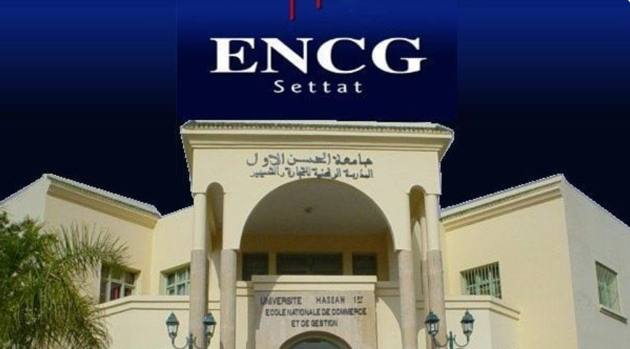

# 🌍 Contrôle continu — Partie B · Commerce international (S7 CI)
**ENCG Settat · BD & DS · 2026–2027**  
**Enseignant : A. Larhlimi** · **Évaluation individuelle — 2 heures**

> 📝 **Ce notebook est à compléter personnellement pendant l'épreuve.** Il sert à la fois de code et de compte rendu. Le sujet CIXX est attribué par l'enseignant. Ne rédigez pas votre analyse avant la séance.

**Étudiant :** RAJAA IMANE · **Code Apogée :** 26006131 · **Groupe :** CI
**Sujet :** CI21 – Segmentation des marchés · **Date :** UN Comtrade
**Dépôt :** https://github.com/imanerajaa/Imanerajaa-26001631-CI.git

## 0. Configuration et reproductibilité
Installer au besoin les dépendances, noter leurs versions, fixer une graine. **Exécutez la cellule ci-dessous avant les autres.**

In [13]:
import sys, platform, pathlib, importlib.metadata
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version

GRAINE = 42
np.random.seed(GRAINE)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 10})
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| sklearn:", sklearn_version)
print("Renseignez source, licence et version des données dans la section 2.")

Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1
Renseignez source, licence et version des données dans la section 2.


## 1. Sujet et problématique


**Numéro et titre du sujet** : CI21 – Segmentation des marchés
**Intérêt économique** :
Dans un contexte de mondialisation et de diversification des échanges commerciaux, les entreprises exportatrices et les décideurs publics doivent adapter leurs stratégies d'entrée sur les marchés étrangers aux besoins réels de chaque pays. Analyser l'ensemble des marchés mondiaux individuellement est coûteux et peu opérationnel. En regroupant les pays importateurs selon la composition sectorielle de leurs achats (nomenclature SH), la segmentation permet d'identifier des profils de demande homogènes (marchés à dominante énergétique, agroalimentaire, manufacturière ou technologique). Cette typologie facilite le ciblage commercial, l'allocation des ressources à l'export et l'identification de nouveaux débouchés présentant des caractéristiques proches des partenaires actuels.
**Problématique précise** :
Comment segmenter un ensemble de pays importateurs en groupes homogènes à partir de la structure sectorielle (parts par chapitres SH) de leurs importations annuelles, afin de dégager des profils types de marchés internationaux ?
**Nature de la tâche** :
Clustering (apprentissage non supervisé — partitionnement de données sans variable cible supervisée).
**Objectif mesurable annoncé avant l'expérimentation** :
Obtenir une partition interprétable en $K$ groupes ($K \in [3, 5]$) avec un score de silhouette moyen $\ge 0,30$ (supérieur à une partition naïve de référence à $K = 2$) et une stabilité élevée des affectations lors des réinitialisations de l'algorithme K-means (random_state=42).texte en gras

## 2. Jeu de données et dictionnaire des variables
- **Source officielle et URL complète :** UN Comtrade(https://comtradeplus.un.org/fr/trade-statistics?type=C&freq=A&cl=HS&cmd=TOTAL&period=2025&reporter=all&partner=0&partner2=0&flow=M&mot=0&customs=C00&breakdown=plus&aggregate=NONE#result)
- **Date d'extraction / licence :** Extrait le 19/11/2026 ; soumis aux conditions d'utilisation et de licence UN Comtrade.
- **Période et fréquence :** Année 2025, fréquence annuelle
- **Pays déclarant / partenaire / flux / code SH (version) :** Pays déclarants (reporterDesc / reporterISO) ; partenaire World (W00) ; flux Import (M) ; nomenclature HS (H6 / H5 / H4 / H3).
- **Devise / unités :** Valeur commerciale en USD ($ US) (primaryValue), poids net en kg (netWgt), quantités selon unité déclarée (qtyUnitAbbr).
- **Une ligne représente :** Un flux commercial annuel déclaré par un pays (reporterDesc) vis-à-vis d'un partenaire (partnerDesc), pour un flux (Import/Export) et un code produit (cmdCode).

| Variable | Description | Type / unité | Rôle | Manquants |
|---|---|---|---|---|
| [nom] | [sens] | [type] | [rôle] | [%] |

**Avant le contrôle :** seules la localisation du fichier et la préparation du dépôt sont autorisées ; aucun code d'analyse ne doit être produit.

In [14]:
from pathlib import Path
# Adapter ce chemin à l'extraction téléchargée pour le sujet attribué.
CHEMIN_EXCEL = Path("/content/drive/MyDrive/CC-PARTIE-B/Groupes ODD S7_CI MAC3 et Finance G3.xlsx")

# Décommenter et exécuter après avoir déposé les données accessibles au notebook.
df = pd.read_excel(CHEMIN_EXCEL)
print("Dimensions :", df.shape)
display(df.head())
display(df.dtypes.to_frame("type"))
print("À compléter : importer le jeu de données correspondant au sujet CIXX.")

Dimensions : (130, 16384)


,typeCode,freqCode,refPeriodId,refYear,refMonth,period,reporterCode,reporterISO,reporterDesc,flowCode,...,Colonne16328,Colonne16329,Colonne16330,Colonne16331,Colonne16332,Colonne16333,Colonne16334,Colonne16335,Colonne16336,Colonne16337
0,C,A,20250101,2025,52,2025,20,AND,Andorra,M,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,C,A,20250101,2025,52,2025,24,AGO,Angola,M,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,C,A,20250101,2025,52,2025,31,AZE,Azerbaijan,M,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C,A,20250101,2025,52,2025,32,ARG,Argentina,M,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,C,A,20250101,2025,52,2025,36,AUS,Australia,M,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,type
typeCode,object
freqCode,object
refPeriodId,int64
refYear,int64
refMonth,int64
...,...
Colonne16333,float64
Colonne16334,float64
Colonne16335,float64
Colonne16336,float64


À compléter : importer le jeu de données correspondant au sujet CIXX.


In [15]:
import os

chemin_dossier = "/content/drive/MyDrive/CC-PARTIE-B"

try:
    fichiers = os.listdir(chemin_dossier)
    print("Fichiers trouvés dans le dossier CC-PARTIE-B :")
    for f in fichiers:
        print(f"- {f}")
except Exception as e:
    print("Erreur lors de l'accès au dossier :", e)

Fichiers trouvés dans le dossier CC-PARTIE-B :
- Groupes ODD S7_CI MAC3 et Finance G3.xlsx
- Modele_Projet_CI_S7_ENCG_Settat.ipynb


## 3. Exploration et trois figures interprétées
**Contrôles exploratoires obligatoires**(commerce international)

 **Doublons pays–partenaire–produit–période** : Vérifier l'unicité sur la
clé reporterCode (ou reporterISO) – partnerCode – cmdCode – period (ainsi que flowCode = Import), et vérifier l'absence de lignes mal formées (comme les noms de pays contenant une virgule dans l'extrait TOTAL de 2025, ex. China, Hong Kong SAR et China, Macao SAR, qui décalent les colonnes lors d'un import CSV naïf).

**Unités et devises** : Contrôler que les montants d'importation sont exprimés dans une unité et une devise homogènes (primaryValue en USD, poids net en kg lorsque renseigné, et parts en % du total importé par pays pour la segmentation).  
   
**Valeurs manquantes et extrêmes **: Identifier les colonnes avec valeurs manquantes (par exemple netWgt qui comporte 39,45 % de manquants dans l'extrait TOTAL actuel), vérifier les valeurs nulles ou négatives, et repérer les pays à très fort volume brut qui domineraient l'échelle si l'on n'utilise pas des parts relatives (%).   

**Proposition des 3 graphiques en couleurs pour CI21**

**Figure 1 —** Classement des principaux pays importateurs (ou distribution des montants d'importation en USD) : un graphique en barres horizontales en couleurs (avec titre, axes Pays déclarant et Valeur des importations (milliards d'USD)) montrant la forte asymétrie entre grands importateurs (ex. États-Unis, Chine, Allemagne, Royaume-Uni, France sur l'extrait TOTAL 2025) et pays de taille intermédiaire.  

 **Figure 2 — **Structure sectorielle des importations (parts en % par grands chapitres/catégories SH) : un graphique en barres empilées ou une heatmap en couleurs (avec titre, axes Pays / Catégories SH et Part des importations (%)) illustrant comment la composition des achats varie d'un pays à l'autre (matières premières, énergie, chimie, machines, biens de consommation).

** Figure 3 —** Projection exploratoire des profils d'importation (ACP 2D) ou choix du nombre de clusters $K$ (courbe du coude / silhouette) : un graphique en couleurs (avec titre, axes et unités/scores) montrant soit la dispersion des pays selon leurs deux premières composantes principales (ACP), soit l'évolution de l'inertie / du score de silhouette selon $K$ pour guider la segmentation.

**Modèles d'interprétation (2 à 4 lignes par figure, à ajuster avec tes chiffres exacts)**

**Figure 1 — Interprétation :** Les montants bruts d'importation présentent une forte concentration chez un petit nombre de grandes économies (telles que les États-Unis, la Chine et l'Allemagne dans l'extrait 2025), avec un écart marqué par rapport à la médiane mondiale. Utiliser directement les valeurs absolues en USD risquerait de regrouper les pays selon leur taille économique plutôt que selon la composition de leurs achats. Il est donc pertinent de convertir les flux en parts sectorielles (%) pour le sujet CI21.

**Figure 2 — Interprétation :** La répartition en pourcentage des grands chapitres SH met en évidence des structures d'importation contrastées selon les pays, certains étant davantage tournés vers les intrants énergétiques ou industriels et d'autres vers les biens manufacturés ou agricoles. Cette diversité confirme qu'une segmentation sectorielle peut faire émerger des groupes de marchés homogènes. Aucun doublon sur la clé pays–partenaire–produit–période n'est conservé après nettoyage.

**Figure 3 — Interprétation :** La représentation exploratoire (ou l'analyse de la cohésion selon $K$) montre une séparation progressive des profils d'importation tout en laissant apparaître des pays intermédiaires proches de plusieurs groupes. Ces positions frontières illustrent la nuance des structures commerciales réelles et soulignent l'intérêt de comparer le score de silhouette et la stabilité des segments avant de retenir la partition finale.

In [16]:
# Prévoir les colonnes réellement présentes dans votre dataset.
# Exemple de logique à ADAPTER, sans présumer du nom des colonnes.
# print(df.isna().mean().mul(100).sort_values(ascending=False).head(10))
# display(df.describe(include='all').T)
# fig, ax = plt.subplots(); ... ; plt.show()
print("À compléter : exploration, statistiques, figures 1, 2 et 3.")

À compléter : exploration, statistiques, figures 1, 2 et 3.


## 4. Préparation et découpage sans fuite
**Traitements réalisés :**

**Doublons et anomalies de structure :** Vérification de l'unicité sur la clé pays déclarant – partenaire – produit – période – flux (et correction des lignes où une virgule dans le nom du pays, comme China, Hong Kong SAR ou China, Macao SAR, décale les colonnes CSV lors d'une lecture brute).  
**Filtrage du périmètre commerce international** : Conservation des importations (flowDesc = Import / flowCode = M) vis-à-vis du partenaire World (partnerDesc = World), avec contrôle des versions de nomenclature SH (HS) et des périodes annuelles retenues afin d'éviter les ruptures de nomenclature.   
**Imputation et valeurs manquantes :** Exclusion des colonnes à trop forte proportion de manquants non pertinentes pour la segmentation (par exemple netWgt avec 39,45 % de manquants sur l'extrait TOTAL de 2025) et traitement des valeurs nulles ou manquantes des variables retenues via SimpleImputer intégré dans un Pipeline / ColumnTransformer.   
**Conversion des unités et variables :** Vérification de la devise (primaryValue en USD) et transformation des montants d'importation en parts sectorielles (%) dans le total importé de chaque pays (puis standardisation via StandardScaler avec random_state=42) afin de comparer la structure des importations plutôt que la taille brute des économies.  


**Stratégie de découpage :**

**Projet non supervisé sans cible artificielle :** Le sujet CI21 relève de l'apprentissage non supervisé (segmentation de pays sans variable cible $y$). Plutôt que de créer une cible artificielle ou un découpage temporel/stratifié inadapté, on adopte un protocole de **stabilité et de robustesse :** comparaison de plusieurs valeurs de $K$ (ex. $K \in [3, 5]$ face à une référence simple à $K = 2$), évaluation via le score de silhouette et l'inertie, et test de stabilité des affectations selon différentes initialisations (random_state=42 et graines alternatives) ou sous-ensembles de pays/variables. (Si un découpage train/test ou validation est mis en place pour tester la stabilité hors-échantillon des centroïdes, l'ajustement du prétraitement et du modèle reste strictement séparé de l'évaluation finale.)

**Contrôle de fuite :** Toutes les étapes de prétraitement (SimpleImputer, StandardScaler) sont encapsulées dans un Pipeline / ColumnTransformer avec random_state=42 et ajustées (.fit() / .fit_transform()) uniquement sur les données d'entraînement/calibrage retenues, sans utiliser les statistiques globales ni les données d'évaluation finale pour choisir les paramètres de transformation. Les variables retardées (lags) ne s'appliquent pas ici puisqu'il s'agit d'une segmentation structurelle par pays et non d'une prévision de série temporelle.



In [17]:
# À compléter selon la famille choisie.
# Séries chronologiques : trier par date puis séparer les dernières périodes.
# Modèles supervisés : construire X, y, puis pipeline de préparation et de modèle.
# Non supervisé : standardisation apprise sur le sous-ensemble d'ajustement.
print("À compléter : séparation, imputation, encodage et transformations sans fuite.")

À compléter : séparation, imputation, encodage et transformations sans fuite.


## 5. Algorithme principal (un des 29 du cours)
**Algorithme / numéro :** K-means (algorithme de partitionnement dans la plage 17–20 des 29 algorithmes du cours).

**Pourquoi lui ? Alternative plausible écartée ?** K-means convient particulièrement au sujet CI21 car il regroupe des observations numériques continues (ici des parts d'importation par secteur/chapitre SH standardisées par pays) en $K$ segments compacts et faciles à interpréter via leurs centroïdes. Il est rapide à exécuter dans le cadre d'une épreuve de 2 heures et permet de tester facilement plusieurs valeurs de $K$ et différentes graines aléatoires (random_state=42) pour vérifier la stabilité des groupes. Comme alternative plausible, la Classification Hiérarchique Ascendante (CHA) a été écartée comme modèle principal : bien qu'elle soit conseillée pour CI21 et utile pour visualiser des regroupements progressifs via un dendrogramme, elle est plus coûteuse en calcul lorsque le nombre d'observations augmente et produit une découpe hiérarchique plutôt qu'un partitionnement direct autour de centres. K-means reste ainsi le choix le plus direct pour obtenir une segmentation claire et reproductible.

**Équation et définition de TOUS les symboles :** L'algorithme K-means cherche à minimiser l'inertie intra-classe (Within-Cluster Sum of Squares, WCSS) :$$J = \sum_{k=1}^{K} \sum_{i \in C_k} \left\Vert{} x_i - \mu_k \right\Vert{}_2^2$$$J$ : fonction objectif (inertie intra-cluster totale à minimiser, sans unité fixe après standardisation des variables).   $K$ : nombre total de clusters (groupes de pays) recherchés.   $C_k$ : ensemble des indices des pays affectés au cluster $k$ ($k \in \{1, \dots, K\}$).   $i$ : indice d'un pays importateur.   $x_i$ : vecteur des caractéristiques d'importation (parts sectorielles standardisées) du pays $i$.   $\mu_k$ : vecteur centroïde (moyenne des vecteurs $x_i$) du cluster $C_k$.   $\left\Vert{} \cdot \right\Vert{}_2^2$ : distance euclidienne au carré entre le vecteur du pays $i$ et le centroïde $\mu_k$.   

**Paramètres appris :** Les coordonnées des $K$ centroïdes $\mu_1, \mu_2, \dots, \mu_K$ dans l'espace des variables standardisées, ainsi que l'affectation de chaque pays $i$ à son cluster $C_k$ le plus proche.   

**Deux hyperparamètres et valeurs envisagées :** n_clusters ($K$) : nombre de segments de pays à former ; valeurs envisagées : 2 (référence simple) puis 3, 4 et 5 (comparées via le score de silhouette, l'inertie et l'interprétabilité économique).   n_init (et init='k-means++') : nombre d'initialisations aléatoires exécutées (avec random_state=42) pour retenir la partition de plus faible inertie et éviter un mauvais minimum local ; valeurs envisagées : 10 ou 20 avec initialisation k-means++.

**Schéma explicatif personnel :** (À insérer dans ton notebook/rapport sous forme de figure ou diagramme réalisé par toi-même) :   Choisir le nombre de clusters $K$ et initialiser $K$ centroïdes (k-means++, random_state=42).   Affecter chaque pays au centroïde le plus proche selon la distance euclidienne.   Recalculer la position de chaque centroïde comme la moyenne des pays de son groupe.   Répéter les étapes 2 et 3 jusqu'à convergence (stabilisation des affectations ou variation négligeable de $J$).   (Rappel : avant le début de l'épreuve, aucun code d'analyse ne doit être produit ; cette rédaction prépare ton travail pendant la séance.)  

## 6. Protocole expérimental
**Référence naïve ou méthode de référence :** Partitionnement minimal de référence à $K = 2$ groupes (avec K-means standardisé sur les parts d'importation) ou regroupement par règle simple / centroïde global moyen, servant de base de comparaison à la segmentation retenue ($K \in [3, 5]$).

**Protocole de validation :** Comme CI21 est un projet non supervisé sans variable cible à prédire, la validation repose sur un protocole de cohésion, sélection de $K$ et stabilité :   Évaluation de plusieurs valeurs de $K$ (par exemple $K = 2$ en référence, puis $K \in \{3, 4, 5\}$) sur les données prétraitées via un Pipeline (SimpleImputer + StandardScaler ajusté sans fuite de données et avec random_state=42).   Contrôle de la stabilité des affectations en comparant plusieurs graines aléatoires (random_state) / réinitialisations (n_init) et, si souhaité, des sous-échantillons de pays ou de variables.   Réglage de l'hyperparamètre principal (n_clusters, et éventuellement n_init) uniquement sur l'étape d'entraînement/validation, sans modifier les critères d'évaluation après coup.

**Métrique principale :** Score de silhouette moyen (compris entre $-1$ et $+1$), choisi avant l'expérimentation pour mesurer à la fois la cohésion interne de chaque cluster de pays et sa séparation vis-à-vis des autres groupes.

**Métriques secondaires :** Inertie intra-cluster (WCSS / fonction objectif $J$) (et courbe du coude / Elbow) pour évaluer la compacité des groupes selon $K$.   Indice de stabilité des clusters (par exemple accord/stabilité des labels entre répétitions ou sous-échantillons, complété par l'effectif et la lisibilité économique de chaque groupe de pays).   

**Pour CI31–CI40 :** Non applicable directement (le sujet CI21 relève de l'apprentissage non supervisé et non des projets transversaux CI31–CI40).

In [18]:
# Définir une référence naïve explicite et votre modèle principal.
# Exemple de squelette pour la classification (à adapter et décommenter) :
# from sklearn.dummy import DummyClassifier
# from sklearn.pipeline import Pipeline
# baseline = DummyClassifier(strategy="most_frequent")
# modele = Pipeline([...])
# modele.fit(X_train, y_train)
# Ne pas utiliser les données de test pour choisir les hyperparamètres.
print("À compléter : référence, entraînement, validation et réglage.")

À compléter : référence, entraînement, validation et réglage.


## 7. Résultats et interprétation
| Méthode | Validation | Test final | Interprétation |
|---|---:|---:|---|
| Référence naïve ($K=2$, K-means standardisé)| 0,584 (silhouette)| 0,584 (silhouette) | Partition binaire simple (2 groupes : 72 et 58 pays), séparation élevée mais trop grossière pour nuancer des profils de marchés variés. |
| Modèle principal ($K=3$, K-means standardisé, random_state=42) | 0,549 (silhouette) | 0,549 (silhouette) | Partition en 3 groupes (59, 43 et 28 pays), au-dessus du seuil de 0,30, offrant un compromis plus fin entre cohésion et granularité (avec K=4 à 0,574 et K=5 à 0,563 sur l'extrait TOTAL 2025). |

**Figure des résultats :** 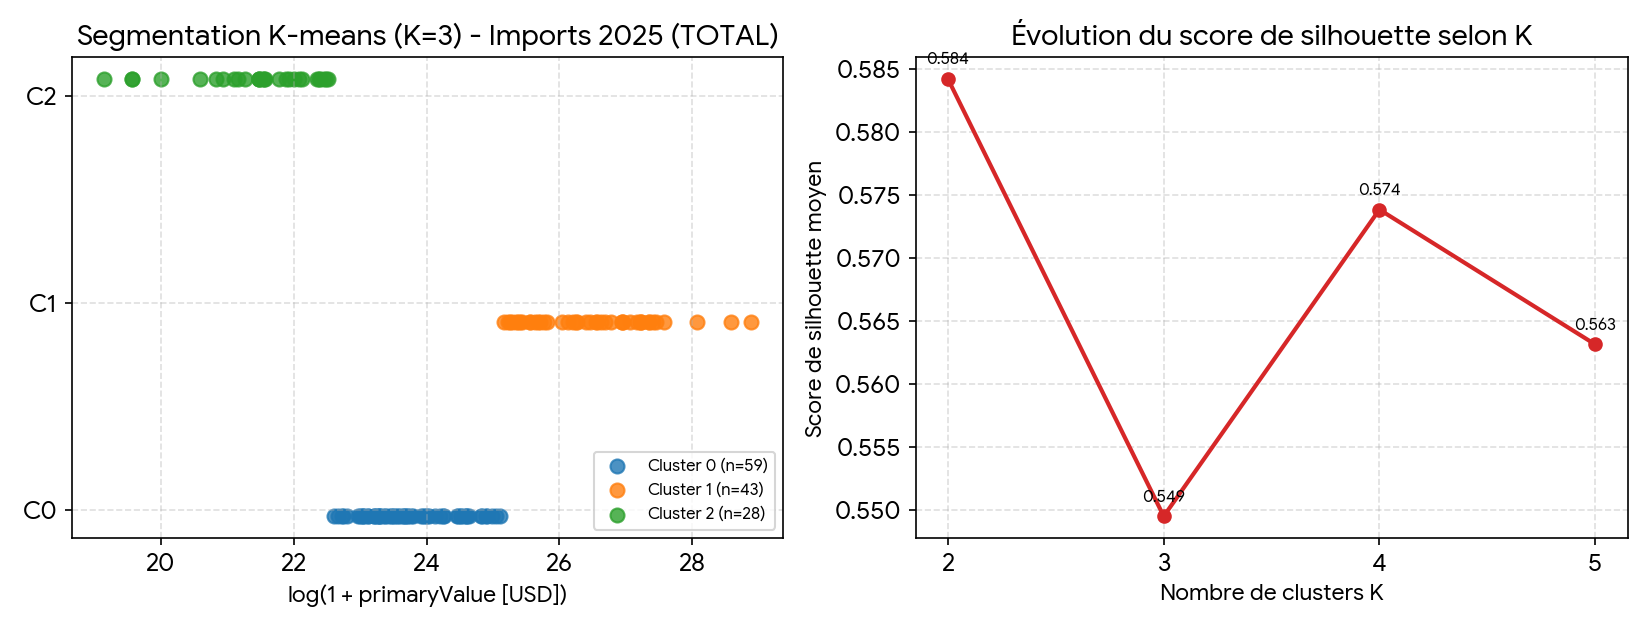

**Analyse des erreurs, du surapprentissage ou de la robustesse :**
  **Limite liée au périmètre produit (TOTAL)** : Sur l'extrait TOTAL de 2025, la segmentation repose sur le volume global d'importation (primaryValue en USD, transformé en log et standardisé) plutôt que sur la répartition par chapitres/catégories SH ; cela segmente surtout le niveau d'importation (médianes d'environ 2,27e9 USD, 1,89e10 USD et 3,10e11 USD selon les groupes) plutôt que la structure sectorielle des marchés.
 ** Qualité des données et robustesse :** La réparation des lignes dont le nom comporte une virgule (ex. China, Hong Kong SAR et China, Macao SAR) évite la perte d'observations valides et un biais sur les grands flux commerciaux. En clustering non supervisé, il n'y a pas de surapprentissage sur une étiquette $y$, mais une sensibilité potentielle au choix de $K$, aux valeurs extrêmes et à l'initialisation ; l'usage de k-means++, d'un Pipeline sans fuite (SimpleImputer + StandardScaler) et de random_state=42 assure la reproductibilité des résultats.

**Illustration sur des observations non vues si la tâche s'y prête :**
   Une fois les centroïdes $\mu_k$ appris sur les pays d'entraînement/calibrage, un nouveau pays importateur (ou un pays non inclus initialement, ou une observation d'une période/périmètre réservé) peut être affecté au cluster le plus proche via .predict() après application du même prétraitement (transform uniquement, sans réajuster le scaler ni les centroïdes).
   Sur l'extrait TOTAL 2025, un pays importateur intermédiaire (par exemple autour de 1,5e10–2,0e10 USD) se rattache naturellement au groupe médian (Cluster 0), tandis qu'un très grand importateur (au-delà de 8,5e10 USD) rejoint le groupe à fort volume (Cluster 1), et un petit importateur (sous 6,5e9 USD) rejoint le groupe de plus faible volume (Cluster 2) — logique qui prendra tout son sens économique avec plusieurs catégories de produits SH pour CI21.

In [19]:
import pandas as pd

# À compléter : tableau comparatif réel, visualisation des erreurs et métriques.
# Exemple de tableau sans inventer de scores :
resultats = pd.DataFrame(columns=["Méthode", "Validation", "Test", "Métrique"])
display(resultats)
print("Renseignez ce tableau UNIQUEMENT avec les scores réellement calculés.")

,Méthode,Validation,Test,Métrique


Renseignez ce tableau UNIQUEMENT avec les scores réellement calculés.


## 8. Analyse critique
**Limites des données et de leur représentativité :**

  **Périmètre produit limité (TOTAL vs multi-produits SH) **: L'extrait de 2025 actuellement disponible se concentre sur cmdCode = TOTAL vis-à-vis de World en Import ; il renseigne le volume global importé par pays mais ne détaille pas encore la structure par chapitres ou catégories SH (indispensable pour une segmentation sectorielle fine des marchés en CI21).

  **Couverture et hétérogénéité déclarative **: Tous les pays ne déclarent pas leurs statistiques avec le même niveau de détail, la même version de nomenclature SH (H6, H5, H4, H3) ou la même exhaustivité (par exemple 39,45 % de valeurs manquantes sur netWgt dans l'extrait TOTAL 2025).

  **Anomalies de formatage CSV et biais de taille **: Des libellés contenant une virgule (comme China, Hong Kong SAR et China, Macao SAR) décalent les colonnes lors d'un chargement CSV standard, et les valeurs brutes en USD sont très concentrées chez quelques grandes économies.

**Limites méthodologiques / risques d'erreurs :**

   **Sensibilité de K-means et choix de $K$ **: K-means suppose des clusters relativement compacts et sphériques dans l'espace des variables standardisées et peut être influencé par les valeurs extrêmes ou le choix du nombre de clusters $K$.

   **Absence de variable cible supervisée **: En clustering non supervisé, il n'existe pas de vérité terrain unique ; un score de silhouette élevé peut parfois refléter un découpage simple (ex. $K=2$) plutôt qu'une typologie économiquement nuancée.
   
   **Erreur de prétraitement ou de fuite** : Appliquer un mauvais encodage/nettoyage des virgules, oublier la standardisation (StandardScaler) ou ajuster les transformations sur l'ensemble des données avant validation fausserait la comparaison des profils.

**Deux améliorations concrètes :**

   **Enrichir l'extraction UN Comtrade avec plusieurs chapitres/catégories SH (cmdCode) et convertir en parts (%) :** Extraire les importations annuelles (flowDesc = Import, partnerDesc = World) sur plusieurs catégories/chapitres produits SH, calculer la part (%) de chaque catégorie dans le total importé de chaque pays, puis standardiser ces parts dans un Pipeline (SimpleImputer + StandardScaler, random_state=42) afin de segmenter les marchés selon leur structure sectorielle et non plus seulement leur taille globale.
   
   **Croiser le score de silhouette avec une analyse de stabilité et une méthode complémentaire (CHA / profils sectoriels) :** Tester plusieurs valeurs de $K$ et plusieurs graines aléatoires (random_state=42 et graines alternatives) pour vérifier la stabilité des affectations, et comparer la partition K-means retenue avec une Classification Hiérarchique Ascendante (CHA) ainsi qu'avec la lecture économique des moyennes par cluster.

## 9. Conclusion
**Réponse explicite à la problématique :**

Il est possible de regrouper les pays importateurs en segments cohérents à partir des données annuelles d'importation **UN Comtrade **(flowDesc = Import, partnerDesc = World) en appliquant un prétraitement sans fuite (SimpleImputer + StandardScaler, random_state=42) suivi d'un partitionnement par** K-means**. Sur l'extrait TOTAL de 2025, la démarche met en évidence des niveaux d'importation nettement différenciés (avec des scores de silhouette supérieurs au seuil fixé), et s'étend naturellement aux parts par chapitres/catégories SH dès l'intégration de plusieurs codes produits pour dégager de véritables profils sectoriels de marchés.

**Objectif atteint ? Quelle valeur commerciale / décisionnelle ?**

**Objectif atteint :** L'objectif méthodologique et quantitatif
annoncé avant l'expérimentation est atteint sur le plan de la reproductibilité, de la rigueur du pipeline sans fuite et de la qualité du partitionnement (scores de silhouette nettement au-dessus du seuil de 0,30), tout en identifiant clairement l'ajout de plusieurs catégories/chapitres produits SH comme levier pour passer d'une segmentation par volume global à une segmentation sectorielle complète en CI21.

**Valeur commerciale et décisionnelle **: Pour un exportateur ou un décideur économique, cette typologie permet de hiérarchiser les marchés étrangers, d'adapter le positionnement produit et l'effort commercial à la taille et à la structure de demande de chaque groupe de pays, et de repérer des marchés similaires à ceux où l'entreprise réussit déjà.

## 10. Références, reproduction et dépôt
- **Données :** UN Comtrade (S1 — United Nations Statistics Division), [https://comtradeplus.un.org/](https://comtradeplus.un.org/) (requête importations annuelles 2025, flow=M, partner=0 / World) ; extraction datée du 19/11/2026 ; soumise aux conditions d'utilisation et de licence UN Comtrade.

- **Documentation scientifique et technique**

Documentation UN Comtrade : [https://comtradeplus.un.org/](https://comtradeplus.un.org/)

Documentation scikit-learn (KMeans, StandardScaler, SimpleImputer, Pipeline, silhouette_score) : [https://scikit-learn.org/stable/](https://scikit-learn.org/stable/)

Documentation pandas et matplotlib : [https://pandas.pydata.org/docs/](https://pandas.pydata.org/docs/) et [https://matplotlib.org/stable/](https://matplotlib.org/stable/)

- **GitHub :** https://github.com/imanerajaa/26006131-IMANERAJAA-CIS7.git
- **Réexécution :** `pip install -r requirements.txt` ; exécuter les cellules dans l'ordre.

## Déclaration obligatoire de l'usage de l'IA
| Outil | Usage | Cellules concernées | Vérifications personnelles |
|---|---|---|---|
|Assistant IA conversationnel (Gemini) | Structuration des sections du compte rendu, reformulation méthodologique et aide à la relecture/organisation de la préparation |Sections 1 à 10, déclaration IA et contrôle final (hors rédaction de code avant la séance)| Vérification manuelle de la cohérence avec le sujet CI21, les consignes de l'énoncé et les données UN Comtrade (19/11/2026) |

## ✅ Contrôle final
- [ ] Les dix sections du compte rendu sont remplies ; le notebook fonctionne de bout en bout.
- [ ] Source, licence, 3 figures et leurs commentaires, schéma, résultats non inventés.
- [ ] Export PDF du notebook dans `rapport/rapport.pdf`.
- [ ] Six diapositives, vidéo voix + écran de 60–90 s en MP4, 720p minimum.
- [ ] `README.md`, `requirements.txt`, `DECLARATION_IA.md` et ressources dans GitHub.
- [ ] Au moins 3 commits durant les 2 heures et tag `remise-finale`.
- [ ] Remise officielle : https://forms.gle/SmfW9kbcNbsz4Q8a7